In [36]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense,Input,Dropout,Conv2D, MaxPooling2D, Flatten 
import matplotlib.pyplot as plt

In [22]:
df_train=pd.read_csv("D:/Jupyter/DL/3/cifar10/train.csv")
df_test=pd.read_csv("D:/Jupyter/DL/3/cifar10/test.csv")

In [23]:
df_train

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,145,151,156,155,153,153,157,161,161,161,...,68,64,61,63,59,57,56,53,54,2
49996,255,254,255,254,254,254,254,253,254,254,...,61,64,68,64,76,82,79,81,76,6
49997,35,40,42,39,43,45,48,51,53,56,...,94,104,103,96,93,87,77,66,50,9
49998,189,186,185,184,182,181,180,180,181,180,...,166,171,171,172,169,165,169,171,171,1


In [24]:
df_test

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3062,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071
0,158,159,165,166,160,156,162,159,158,159,...,130,123,145,167,182,175,145,124,129,110
1,235,231,232,232,232,232,232,232,232,232,...,108,117,123,133,141,153,163,178,191,199
2,158,158,139,132,166,182,187,193,199,205,...,45,46,44,44,43,52,37,8,3,7
3,155,167,176,190,177,166,168,166,170,179,...,52,55,70,103,105,72,53,50,52,50
4,65,70,48,30,23,40,44,45,45,40,...,102,127,156,139,131,130,147,136,146,117
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,76,76,77,76,75,76,76,76,76,78,...,228,185,177,223,239,239,235,236,234,236
9996,81,91,98,106,108,110,80,84,88,90,...,126,107,143,155,156,160,173,129,147,160
9997,20,19,15,15,14,13,12,11,10,9,...,114,112,68,50,52,52,51,50,53,47
9998,25,15,23,17,23,51,74,91,114,137,...,87,84,83,84,79,78,78,80,81,80


In [25]:
df_train.columns

Index(['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5',
       'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9',
       ...
       'pixel_3063', 'pixel_3064', 'pixel_3065', 'pixel_3066', 'pixel_3067',
       'pixel_3068', 'pixel_3069', 'pixel_3070', 'pixel_3071', 'label'],
      dtype='object', length=3073)

In [26]:
df_train.dropna

<bound method DataFrame.dropna of        pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0           59       43       50       68       98      119      139      145   
1          154      126      105      102      125      155      172      180   
2          255      253      253      253      253      253      253      253   
3           28       37       38       42       44       40       40       24   
4          170      168      177      183      181      177      181      184   
...        ...      ...      ...      ...      ...      ...      ...      ...   
49995      145      151      156      155      153      153      157      161   
49996      255      254      255      254      254      254      254      253   
49997       35       40       42       39       43       45       48       51   
49998      189      186      185      184      182      181      180      180   
49999      229      236      234      231      236      242      246      2

In [27]:
X_train=df_train.drop("label",axis=1).values
y_train=df_train["label"].values.astype(int)

In [28]:
X_test=df_test.fillna(0).values

In [29]:
X_train=X_train/255.0
X_test=X_test/255.0

In [30]:
X_train = X_train.reshape(-1, 32, 32, 3)
X_test = X_test.reshape(-1, 32, 32, 3)

In [31]:
model = Sequential([Input(shape=(32,32,3)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
                    
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')])

In [32]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [33]:
history=model.fit(X_train,y_train,epochs=20,batch_size=64,validation_split=0.2)

Epoch 1/20
625/625 [==============================] - 123s 192ms/step - loss: 1.6070 - accuracy: 0.4306 - val_loss: 1.4617 - val_accuracy: 0.4907
Epoch 2/20
625/625 [==============================] - 95s 152ms/step - loss: 1.2942 - accuracy: 0.5447 - val_loss: 1.2364 - val_accuracy: 0.5699
Epoch 3/20
625/625 [==============================] - 69s 111ms/step - loss: 1.1613 - accuracy: 0.5938 - val_loss: 1.1605 - val_accuracy: 0.5935
Epoch 4/20
625/625 [==============================] - 69s 111ms/step - loss: 1.0762 - accuracy: 0.6279 - val_loss: 1.1306 - val_accuracy: 0.6119
Epoch 5/20
625/625 [==============================] - 70s 112ms/step - loss: 1.0057 - accuracy: 0.6511 - val_loss: 1.1459 - val_accuracy: 0.6047
Epoch 6/20
625/625 [==============================] - 66s 105ms/step - loss: 0.9394 - accuracy: 0.6742 - val_loss: 1.1089 - val_accuracy: 0.6159
Epoch 7/20
625/625 [==============================] - 67s 107ms/step - loss: 0.8855 - accuracy: 0.6955 - val_loss: 1.1079 - val_a

In [34]:
print(f"\nTest Accuracy:", history.history['accuracy'][-1])


Test Accuracy: 0.8969500064849854


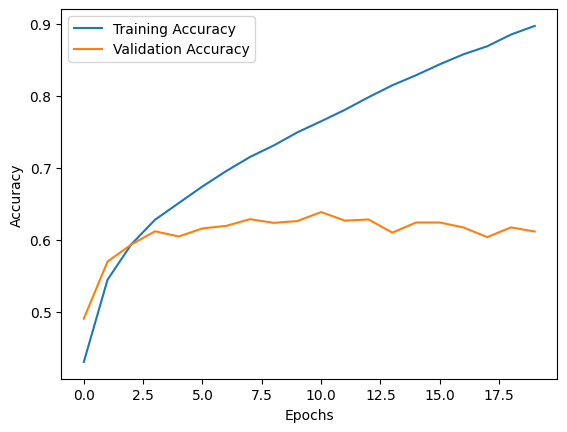

In [39]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()